In [1]:
# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from scipy.stats import fisher_exact

In [2]:
# ============================================================
# 2. PATHS AND SETTINGS
# ============================================================

PROJECT_DIR = Path(
    "/data/gent/vo/000/gvo00070/vsc48277/yujin_project"
)

STITCH_OUTPUT_DIR = (
    PROJECT_DIR
    / "40k_subset_0_cellpose_fullcell_stitch3d_tiled_filtered"
)


# ------------------------------------------------------------
# VSI
# ------------------------------------------------------------

VSI_CSV = (
    STITCH_OUTPUT_DIR
    / "ovrlpy_vsi_maxproj_masks"
    / "stack_vsi_summary_maxproj_mask.csv"
)


# ------------------------------------------------------------
# Bimodality
# ------------------------------------------------------------

BIMODALITY_CSV = (
    STITCH_OUTPUT_DIR
    / "ordered_bimodality_scores_dapi_maxproj_updated"
    / "stack_ordered_bimodality_scores_dapi_maxproj.csv"
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

OUT_DIR = (
    STITCH_OUTPUT_DIR
    / "vsi_bimodality_analysis"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# ANALYSIS SETTINGS
# =============================================================================

# VSI quality-control
MIN_VSI_PIXELS = 10


# Primary low-VSI threshold
VSI_CUTOFF = 0.80

# Bimodality
BIMODALITY_SCORE_CUTOFF = 0


# For sensitivity analysis
VSI_CUTOFFS = np.arange(
    0.50,
    0.901,
    0.025,
)

In [3]:
# =============================================================================
# LOAD TABLES
# =============================================================================

vsi_df = pd.read_csv(
    VSI_CSV
)

bim_df = pd.read_csv(
    BIMODALITY_CSV
)


print("VSI shape:")
print(vsi_df.shape)

print("\nBimodality shape:")
print(bim_df.shape)


print("\nVSI columns:")
print(vsi_df.columns.tolist())

print("\nBimodality columns:")
print(bim_df.columns.tolist())

VSI shape:
(68003, 17)

Bimodality shape:
(68003, 32)

VSI columns:
['stack_id', 'maxproj_cell_id', 'roi_y_min', 'roi_y_max', 'roi_x_min', 'roi_x_max', 'mean_vsi', 'median_vsi', 'std_vsi', 'min_vsi', 'max_vsi', 'mean_signal', 'n_vsi_pixels', 'fraction_low_vsi_pixels', 'minimum_signal_threshold', 'low_vsi_threshold', 'mask_definition']

Bimodality columns:
['stack_id', 'intensity_column', 'bimodality_method', 'minimum_peak_distance_threshold', 'minimum_raw_valley_depth_threshold', 'n_z_layers', 'maxproj_cell_id', 'maxproj_mask_area_pixels', 'linked_union_area_pixels', 'maxproj_overlap_pixels', 'maxproj_overlap_fraction_of_linked_stack', 'maxproj_overlap_fraction_of_cell', 'roi_type', 'roi_y_min', 'roi_y_max', 'roi_x_min', 'roi_x_max', 'profile_status', 'n_profile_values', 'n_selected_peaks', 'peak_1_z', 'peak_2_z', 'peak_1_intensity', 'peak_2_intensity', 'peak_distance', 'valley_z', 'valley_intensity', 'raw_valley_drop', 'raw_valley_depth', 'peak_balance', 'ordered_bimodality_score', 'i

In [4]:
# =============================================================================
# DATA TYPES
# =============================================================================

vsi_df["stack_id"] = pd.to_numeric(
    vsi_df["stack_id"],
    errors="raise",
).astype(np.int64)


bim_df["stack_id"] = pd.to_numeric(
    bim_df["stack_id"],
    errors="raise",
).astype(np.int64)


vsi_numeric_columns = [
    "mean_vsi",
    "n_vsi_pixels",
]


for column in vsi_numeric_columns:

    if column in vsi_df.columns:

        vsi_df[column] = pd.to_numeric(
            vsi_df[column],
            errors="coerce",
        )


bim_numeric_columns = [
    "ordered_bimodality_score",
    "raw_valley_depth",
    "raw_valley_drop",
    "peak_distance",
    "peak_1_z",
    "peak_2_z",
    "valley_z",
    "peak_1_intensity",
    "peak_2_intensity",
    "valley_intensity",
]


for column in bim_numeric_columns:

    if column in bim_df.columns:

        bim_df[column] = pd.to_numeric(
            bim_df[column],
            errors="coerce",
        )


# Make boolean robust in case pandas read it as string
if "is_ordered_bimodal" in bim_df.columns:

    if bim_df["is_ordered_bimodal"].dtype == object:

        bim_df["is_ordered_bimodal"] = (
            bim_df["is_ordered_bimodal"]
            .astype(str)
            .str.lower()
            .map(
                {
                    "true": True,
                    "false": False,
                }
            )
        )


print("Data types prepared.")

Data types prepared.


In [5]:
# =============================================================================
# CHECK NEW BIMODALITY RESULTS
# =============================================================================

print("Profile status counts:\n")

print(
    bim_df[
        "profile_status"
    ]
    .value_counts(
        dropna=False
    )
)


print("\nScore summary:\n")

print(
    bim_df[
        "ordered_bimodality_score"
    ]
    .describe()
)


print(
    "\nNumber with score > 0:",
    int(
        (
            bim_df[
                "ordered_bimodality_score"
            ]
            > 0
        ).sum()
    )
)


if "is_ordered_bimodal" in bim_df.columns:

    print(
        "Number with is_ordered_bimodal=True:",
        int(
            bim_df[
                "is_ordered_bimodal"
            ]
            .fillna(False)
            .sum()
        )
    )

Profile status counts:

profile_status
top_two_peaks_too_close    67212
valid_two_maxima_valley      780
constant_profile              11
Name: count, dtype: int64

Score summary:

count    68003.000000
mean         0.000953
std          0.012248
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.443666
Name: ordered_bimodality_score, dtype: float64

Number with score > 0: 780
Number with is_ordered_bimodal=True: 780


In [6]:
# =============================================================================
# MERGE
# =============================================================================

analysis_df = vsi_df.merge(
    bim_df,
    on="stack_id",
    how="inner",
    suffixes=(
        "_vsi",
        "_bim",
    ),
)


print(
    "Merged stacks:",
    len(analysis_df)
)

Merged stacks: 68003


In [7]:
# =============================================================================
# QC
# =============================================================================

qc_mask = (
    analysis_df[
        "mean_vsi"
    ].notna()

    &

    analysis_df[
        "ordered_bimodality_score"
    ].notna()

    &

    (
        analysis_df[
            "n_vsi_pixels"
        ]
        >= MIN_VSI_PIXELS
    )
)


qc_df = (
    analysis_df.loc[
        qc_mask
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "Before QC:",
    len(analysis_df)
)

print(
    "After QC:",
    len(qc_df)
)

Before QC: 68003
After QC: 65317


In [8]:
# =============================================================================
# DEFINE GROUPS
# =============================================================================

qc_df["low_vsi"] = (
    qc_df[
        "mean_vsi"
    ]
    <= VSI_CUTOFF
)


qc_df["bimodality_positive"] = (
    qc_df[
        "ordered_bimodality_score"
    ]
    > BIMODALITY_SCORE_CUTOFF
)


qc_df["both"] = (
    qc_df[
        "low_vsi"
    ]
    &
    qc_df[
        "bimodality_positive"
    ]
)


print(
    "Low VSI:",
    int(
        qc_df[
            "low_vsi"
        ].sum()
    )
)


print(
    "Bimodality score > 0:",
    int(
        qc_df[
            "bimodality_positive"
        ].sum()
    )
)


print(
    "Both:",
    int(
        qc_df[
            "both"
        ].sum()
    )
)

Low VSI: 4637
Bimodality score > 0: 638
Both: 87


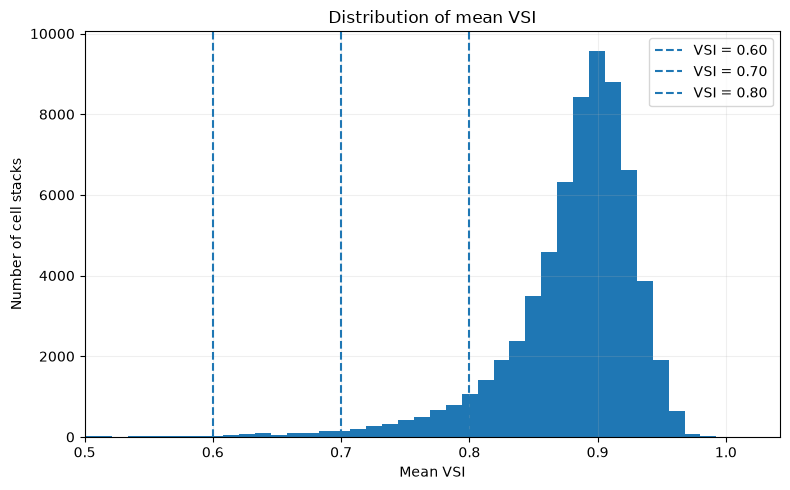

In [9]:
# =============================================================================
# PLOT 1 — VSI DISTRIBUTION
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.hist(
    qc_df[
        "mean_vsi"
    ].dropna(),
    bins=80,
)


for cutoff in [
    0.60,
    0.70,
    0.80,
]:

    ax.axvline(
        cutoff,
        linestyle="--",
        linewidth=1.5,
        label=f"VSI = {cutoff:.2f}",
    )


ax.set_xlabel(
    "Mean VSI"
)

ax.set_ylabel(
    "Number of cell stacks"
)

ax.set_title(
    "Distribution of mean VSI"
)

ax.set_xlim(
    left=0.50
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "01_mean_vsi_distribution.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

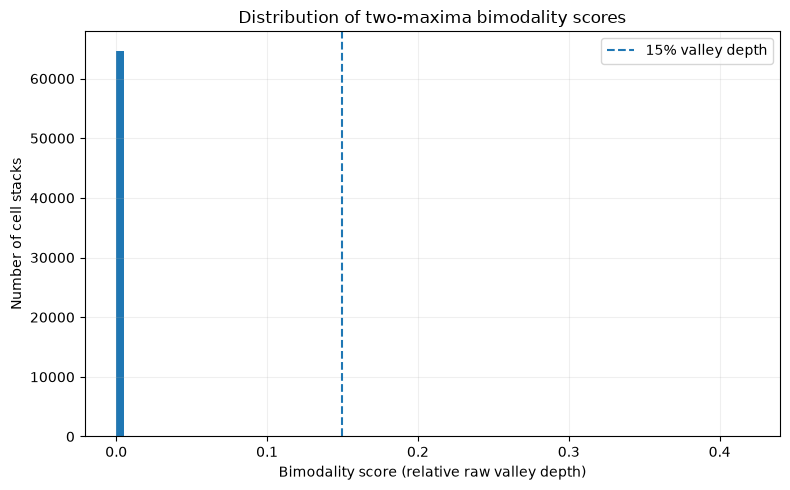

In [10]:
# =============================================================================
# PLOT 2A — ALL BIMODALITY SCORES
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.hist(
    qc_df[
        "ordered_bimodality_score"
    ],
    bins=80,
)


ax.axvline(
    0.15,
    linestyle="--",
    linewidth=1.5,
    label="15% valley depth",
)


ax.set_xlabel(
    "Bimodality score (relative raw valley depth)"
)

ax.set_ylabel(
    "Number of cell stacks"
)

ax.set_title(
    "Distribution of two-maxima bimodality scores"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "02a_bimodality_score_distribution_all.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

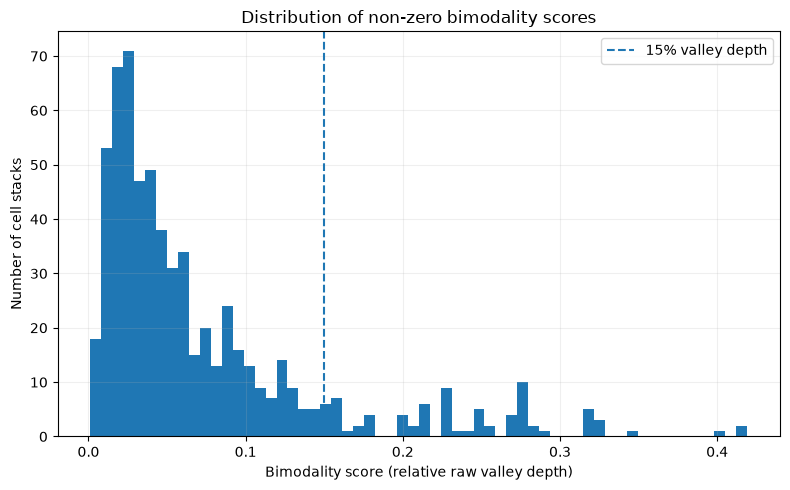

Nonzero scores: 638


In [11]:
# =============================================================================
# PLOT 2B — NONZERO SCORES
# =============================================================================

nonzero_score_df = qc_df.loc[
    qc_df[
        "ordered_bimodality_score"
    ]
    > 0
].copy()


fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.hist(
    nonzero_score_df[
        "ordered_bimodality_score"
    ],
    bins=60,
)


ax.axvline(
    0.15,
    linestyle="--",
    linewidth=1.5,
    label="15% valley depth",
)


ax.set_xlabel(
    "Bimodality score (relative raw valley depth)"
)

ax.set_ylabel(
    "Number of cell stacks"
)

ax.set_title(
    "Distribution of non-zero bimodality scores"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "02b_bimodality_score_distribution_nonzero.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()


print(
    "Nonzero scores:",
    len(nonzero_score_df)
)

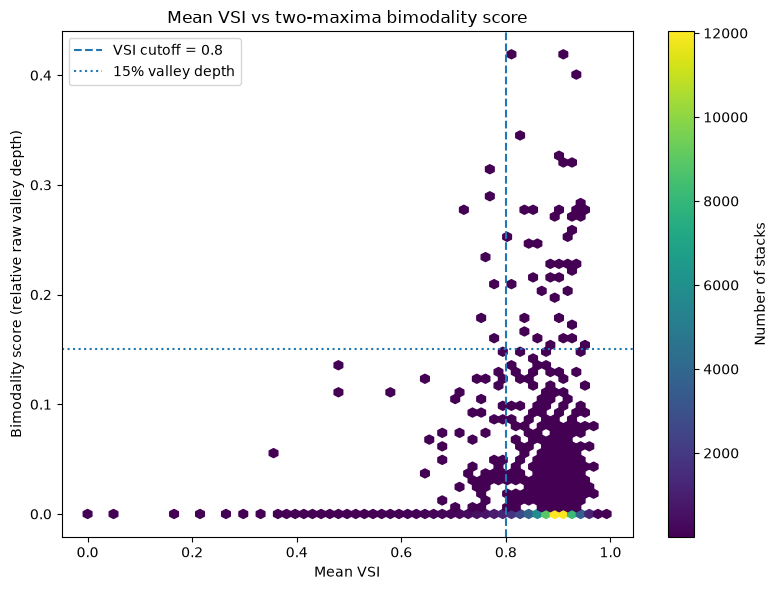

In [12]:
# =============================================================================
# PLOT 3 — VSI VS BIMODALITY
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


hb = ax.hexbin(
    qc_df[
        "mean_vsi"
    ],
    qc_df[
        "ordered_bimodality_score"
    ],
    gridsize=60,
    mincnt=1,
)


ax.axvline(
    VSI_CUTOFF,
    linestyle="--",
    linewidth=1.5,
    label=f"VSI cutoff = {VSI_CUTOFF}",
)


ax.axhline(
    0.15,
    linestyle=":",
    linewidth=1.5,
    label="15% valley depth",
)


ax.set_xlabel(
    "Mean VSI"
)

ax.set_ylabel(
    "Bimodality score (relative raw valley depth)"
)

ax.set_title(
    "Mean VSI vs two-maxima bimodality score"
)


fig.colorbar(
    hb,
    ax=ax,
    label="Number of stacks",
)


ax.legend()

fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "03_vsi_vs_bimodality_hexbin.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

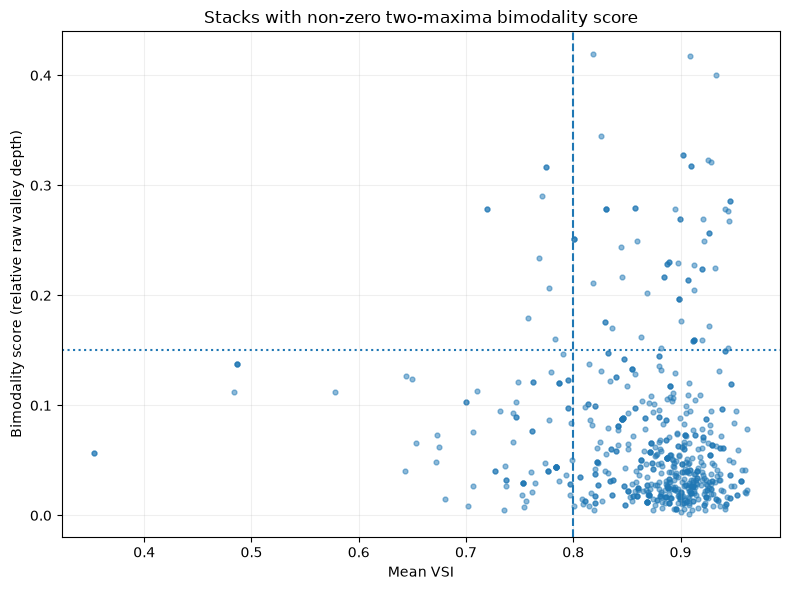

In [13]:
# =============================================================================
# PLOT 4 — NONZERO BIMODALITY ONLY
# =============================================================================

positive_df = qc_df.loc[
    qc_df[
        "ordered_bimodality_score"
    ]
    > 0
].copy()


fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(
    positive_df[
        "mean_vsi"
    ],
    positive_df[
        "ordered_bimodality_score"
    ],
    s=12,
    alpha=0.5,
)


ax.axvline(
    VSI_CUTOFF,
    linestyle="--",
    linewidth=1.5,
)


ax.axhline(
    0.15,
    linestyle=":",
    linewidth=1.5,
)


ax.set_xlabel(
    "Mean VSI"
)

ax.set_ylabel(
    "Bimodality score (relative raw valley depth)"
)

ax.set_title(
    "Stacks with non-zero two-maxima bimodality score"
)

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "04_vsi_vs_bimodality_nonzero_scatter.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [14]:
# =============================================================================
# FOUR GROUPS
# =============================================================================

conditions = [
    (
        ~qc_df["low_vsi"]
        &
        ~qc_df["bimodality_positive"]
    ),

    (
        qc_df["low_vsi"]
        &
        ~qc_df["bimodality_positive"]
    ),

    (
        ~qc_df["low_vsi"]
        &
        qc_df["bimodality_positive"]
    ),

    (
        qc_df["low_vsi"]
        &
        qc_df["bimodality_positive"]
    ),
]


labels = [
    "Neither",
    "Low VSI only",
    "Bimodality only",
    "Both",
]


qc_df[
    "vsi_bimodality_group"
] = np.select(
    conditions,
    labels,
    default="Unknown",
)


group_counts = (
    qc_df[
        "vsi_bimodality_group"
    ]
    .value_counts()
    .reindex(
        labels,
        fill_value=0,
    )
)


print(
    group_counts
)

vsi_bimodality_group
Neither            60129
Low VSI only        4550
Bimodality only      551
Both                  87
Name: count, dtype: int64


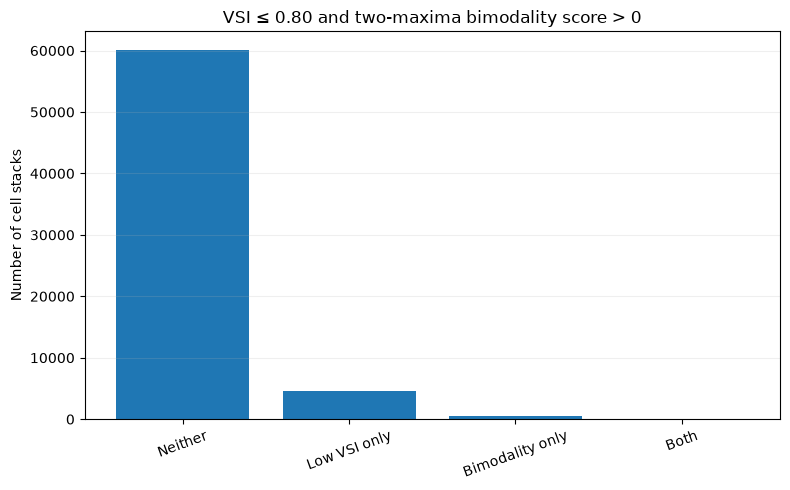

In [15]:
# =============================================================================
# PLOT 5 — FOUR GROUP COUNTS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.bar(
    group_counts.index,
    group_counts.values,
)


ax.set_ylabel(
    "Number of cell stacks"
)

ax.set_title(
    f"VSI ≤ {VSI_CUTOFF:.2f} and two-maxima bimodality score > 0"
)


ax.tick_params(
    axis="x",
    rotation=20,
)


ax.grid(
    axis="y",
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "05_vsi_bimodality_four_groups.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [16]:
# =============================================================================
# VSI QUANTILES
# =============================================================================

quantiles = (
    qc_df[
        "mean_vsi"
    ]
    .quantile(
        [
            0.05,
            0.10,
            0.20,
        ]
    )
)


print(
    quantiles
)

0.05    0.779296
0.10    0.817798
0.20    0.851557
Name: mean_vsi, dtype: float64


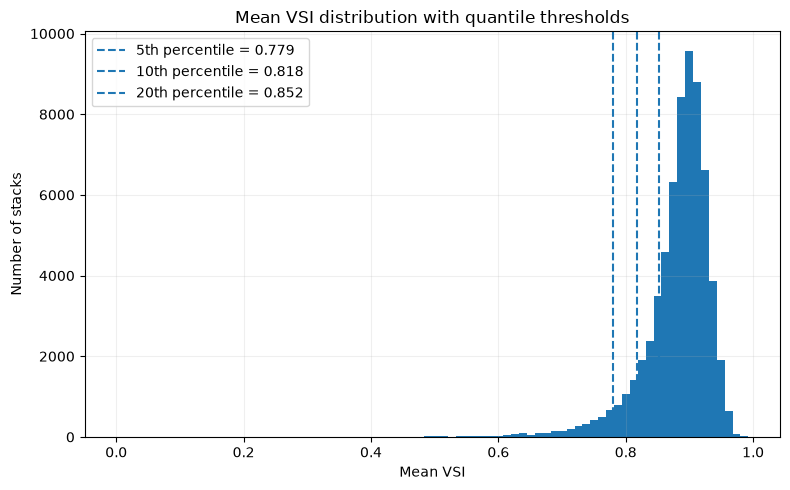

In [17]:
# =============================================================================
# PLOT 6 — VSI QUANTILES
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.hist(
    qc_df[
        "mean_vsi"
    ],
    bins=80,
)


for q, value in quantiles.items():

    ax.axvline(
        value,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"{int(q * 100)}th percentile "
            f"= {value:.3f}"
        ),
    )


ax.set_xlabel(
    "Mean VSI"
)

ax.set_ylabel(
    "Number of stacks"
)

ax.set_title(
    "Mean VSI distribution with quantile thresholds"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "06_vsi_quantile_thresholds.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [18]:
# =============================================================================
# VSI CUTOFF SENSITIVITY
# =============================================================================

sensitivity_rows = []


for cutoff in VSI_CUTOFFS:

    low = (
        qc_df[
            "mean_vsi"
        ]
        <= cutoff
    )

    bimodal = (
        qc_df[
            "ordered_bimodality_score"
        ]
        > BIMODALITY_SCORE_CUTOFF
    )

    both = (
        low
        &
        bimodal
    )


    sensitivity_rows.append(
        {
            "vsi_cutoff":
                cutoff,

            "n_low_vsi":
                int(
                    low.sum()
                ),

            "percent_low_vsi":
                float(
                    low.mean()
                    * 100
                ),

            "n_both":
                int(
                    both.sum()
                ),

            "percent_all_stacks_both":
                float(
                    both.mean()
                    * 100
                ),
        }
    )


sensitivity_df = pd.DataFrame(
    sensitivity_rows
)


sensitivity_df.head()

,vsi_cutoff,n_low_vsi,percent_low_vsi,n_both,percent_all_stacks_both
0,0.500,78,0.119418,6,0.009186
1,0.525,108,0.165347,6,0.009186
2,0.550,131,0.200560,6,0.009186
3,0.575,175,0.267924,6,0.009186
4,0.600,223,0.341412,7,0.010717


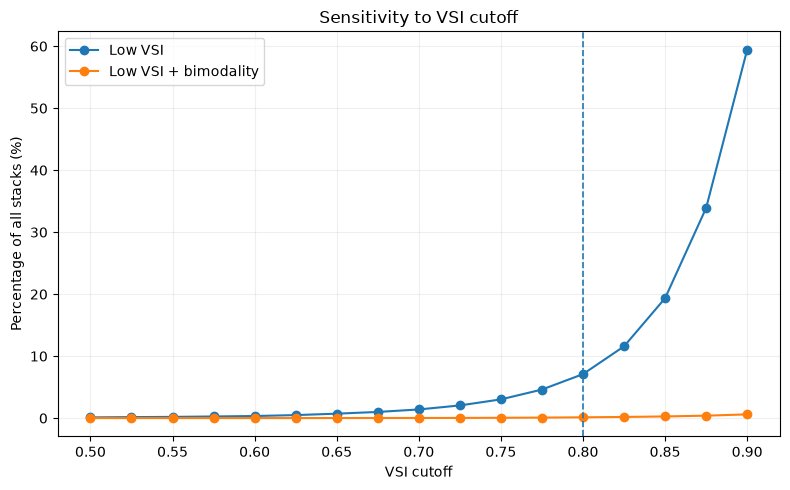

In [19]:
# =============================================================================
# PLOT 7 — VSI SENSITIVITY
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.plot(
    sensitivity_df[
        "vsi_cutoff"
    ],
    sensitivity_df[
        "percent_low_vsi"
    ],
    marker="o",
    label="Low VSI",
)


ax.plot(
    sensitivity_df[
        "vsi_cutoff"
    ],
    sensitivity_df[
        "percent_all_stacks_both"
    ],
    marker="o",
    label="Low VSI + bimodality",
)


ax.axvline(
    VSI_CUTOFF,
    linestyle="--",
    linewidth=1.2,
)


ax.set_xlabel(
    "VSI cutoff"
)

ax.set_ylabel(
    "Percentage of all stacks (%)"
)

ax.set_title(
    "Sensitivity to VSI cutoff"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "07_vsi_cutoff_sensitivity.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [20]:
# =============================================================================
# BIMODALITY RATE WITHIN LOW-VSI GROUP
# =============================================================================

rate_rows = []


overall_bimodality_rate = float(
    qc_df[
        "bimodality_positive"
    ]
    .mean()
)


for cutoff in VSI_CUTOFFS:

    low = (
        qc_df[
            "mean_vsi"
        ]
        <= cutoff
    )


    low_df = qc_df.loc[
        low
    ]


    if len(low_df) == 0:

        bimodality_rate = np.nan

    else:

        bimodality_rate = float(
            low_df[
                "bimodality_positive"
            ]
            .mean()
        )


    rate_rows.append(
        {
            "vsi_cutoff":
                cutoff,

            "n_low_vsi":
                len(
                    low_df
                ),

            "bimodality_rate":
                bimodality_rate,

            "bimodality_rate_percent":
                (
                    bimodality_rate
                    * 100
                    if np.isfinite(
                        bimodality_rate
                    )
                    else np.nan
                ),
        }
    )


rate_df = pd.DataFrame(
    rate_rows
)

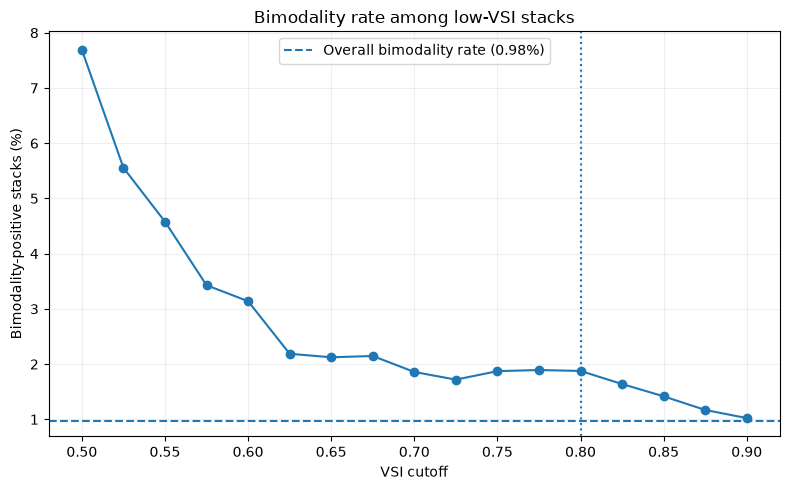

In [21]:
# =============================================================================
# PLOT 8 — BIMODALITY RATE WITHIN LOW-VSI
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.plot(
    rate_df[
        "vsi_cutoff"
    ],
    rate_df[
        "bimodality_rate_percent"
    ],
    marker="o",
)


ax.axhline(
    overall_bimodality_rate
    * 100,
    linestyle="--",
    linewidth=1.5,
    label=(
        "Overall bimodality rate "
        f"({overall_bimodality_rate * 100:.2f}%)"
    ),
)


ax.axvline(
    VSI_CUTOFF,
    linestyle=":",
)


ax.set_xlabel(
    "VSI cutoff"
)

ax.set_ylabel(
    "Bimodality-positive stacks (%)"
)

ax.set_title(
    "Bimodality rate among low-VSI stacks"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "08_bimodality_rate_within_low_vsi.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [22]:
# =============================================================================
# ASSOCIATION / ENRICHMENT
# =============================================================================

association_rows = []


overall_bimodal_rate = float(
    qc_df[
        "bimodality_positive"
    ]
    .mean()
)


for cutoff in VSI_CUTOFFS:

    low = (
        qc_df[
            "mean_vsi"
        ]
        <= cutoff
    )

    bimodal = (
        qc_df[
            "bimodality_positive"
        ]
    )


    a = int(
        (
            low
            &
            bimodal
        ).sum()
    )

    b = int(
        (
            low
            &
            ~bimodal
        ).sum()
    )

    c = int(
        (
            ~low
            &
            bimodal
        ).sum()
    )

    d = int(
        (
            ~low
            &
            ~bimodal
        ).sum()
    )


    table = np.array(
        [
            [a, b],
            [c, d],
        ]
    )


    odds_ratio, p_value = fisher_exact(
        table
    )


    low_total = (
        a
        + b
    )


    low_rate = (
        a
        / low_total
        if low_total > 0
        else np.nan
    )


    fold_enrichment = (
        low_rate
        / overall_bimodal_rate

        if (
            np.isfinite(
                low_rate
            )
            and overall_bimodal_rate > 0
        )

        else np.nan
    )


    association_rows.append(
        {
            "vsi_cutoff":
                cutoff,

            "low_vsi_bimodal":
                a,

            "low_vsi_not_bimodal":
                b,

            "non_low_vsi_bimodal":
                c,

            "non_low_vsi_not_bimodal":
                d,

            "bimodality_rate_low_vsi":
                low_rate,

            "overall_bimodality_rate":
                overall_bimodal_rate,

            "fold_enrichment":
                fold_enrichment,

            "odds_ratio":
                odds_ratio,

            "fisher_p":
                p_value,
        }
    )


association_df = pd.DataFrame(
    association_rows
)

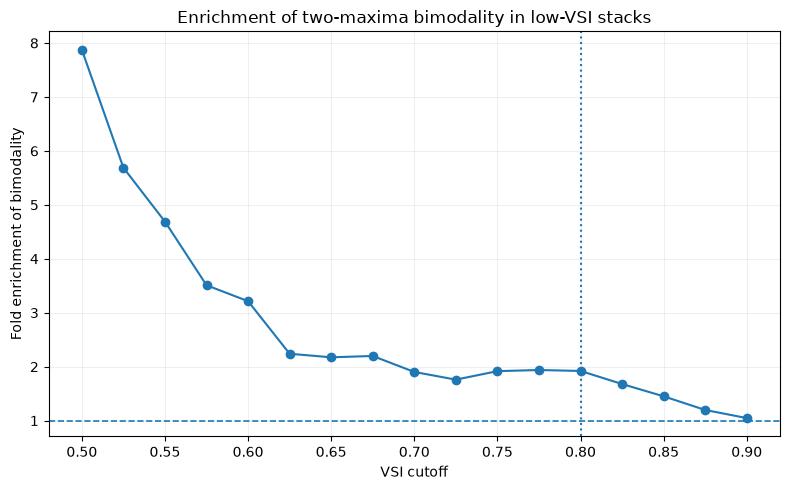

In [23]:
# =============================================================================
# PLOT 9 — ENRICHMENT
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.plot(
    association_df[
        "vsi_cutoff"
    ],
    association_df[
        "fold_enrichment"
    ],
    marker="o",
)


ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.2,
)


ax.axvline(
    VSI_CUTOFF,
    linestyle=":",
)


ax.set_xlabel(
    "VSI cutoff"
)

ax.set_ylabel(
    "Fold enrichment of bimodality"
)

ax.set_title(
    "Enrichment of two-maxima bimodality in low-VSI stacks"
)

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "09_bimodality_enrichment_vs_vsi_cutoff.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [24]:
# =============================================================================
# PRIMARY THRESHOLD SUMMARY
# =============================================================================

primary = association_df.iloc[
    np.argmin(
        np.abs(
            association_df[
                "vsi_cutoff"
            ]
            - VSI_CUTOFF
        )
    )
]


print(
    f"Primary VSI cutoff: "
    f"{primary['vsi_cutoff']:.3f}"
)


print(
    f"Low-VSI & bimodality-positive: "
    f"{int(primary['low_vsi_bimodal'])}"
)


print(
    f"Low-VSI & not bimodality-positive: "
    f"{int(primary['low_vsi_not_bimodal'])}"
)


print(
    f"Bimodality rate within low-VSI: "
    f"{primary['bimodality_rate_low_vsi'] * 100:.3f}%"
)


print(
    f"Overall bimodality rate: "
    f"{primary['overall_bimodality_rate'] * 100:.3f}%"
)


print(
    f"Fold enrichment: "
    f"{primary['fold_enrichment']:.3f}x"
)


print(
    f"Odds ratio: "
    f"{primary['odds_ratio']:.3f}"
)


print(
    f"Fisher p-value: "
    f"{primary['fisher_p']:.3e}"
)

Primary VSI cutoff: 0.800
Low-VSI & bimodality-positive: 87
Low-VSI & not bimodality-positive: 4550
Bimodality rate within low-VSI: 1.876%
Overall bimodality rate: 0.977%
Fold enrichment: 1.921x
Odds ratio: 2.087
Fisher p-value: 6.012e-09


In [25]:
# =============================================================================
# OVERLAP CANDIDATES
# =============================================================================

candidate_df = (
    qc_df.loc[
        (
            qc_df[
                "mean_vsi"
            ]
            <= VSI_CUTOFF
        )
        &
        (
            qc_df[
                "ordered_bimodality_score"
            ]
            > BIMODALITY_SCORE_CUTOFF
        )
    ]
    .copy()
)


candidate_df = (
    candidate_df
    .sort_values(
        [
            "ordered_bimodality_score",
            "mean_vsi",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


print(
    "Number of candidates:",
    len(candidate_df)
)


candidate_columns = [
    "stack_id",
    "mean_vsi",
    "n_vsi_pixels",

    "ordered_bimodality_score",
    "raw_valley_depth",

    "peak_1_z",
    "peak_2_z",
    "peak_distance",

    "valley_z",

    "peak_1_intensity",
    "peak_2_intensity",
    "valley_intensity",

    "is_ordered_bimodal",
    "profile_status",
]


candidate_columns = [
    column
    for column in candidate_columns
    if column in candidate_df.columns
]


candidate_df[
    candidate_columns
].head(
    30
)

Number of candidates: 87


,stack_id,mean_vsi,n_vsi_pixels,ordered_bimodality_score,raw_valley_depth,peak_1_z,peak_2_z,peak_distance,valley_z,peak_1_intensity,peak_2_intensity,valley_intensity,is_ordered_bimodal,profile_status
0,30237,0.774664,145.0,0.316479,0.316479,1,6,5,4,2650.231135,3467.511251,1811.488749,True,valid_two_maxima_valley
1,67047,0.774664,145.0,0.316479,0.316479,1,6,5,4,2650.231135,3467.511251,1811.488749,True,valid_two_maxima_valley
2,12480,0.770624,79.0,0.290404,0.290404,1,6,5,4,2489.396662,2355.176403,1671.224840,True,valid_two_maxima_valley
3,1352,0.719113,166.0,0.278436,0.278436,2,6,4,4,4937.029963,5038.437891,3562.381217,True,valid_two_maxima_valley
4,48362,0.719113,166.0,0.278436,0.278436,2,6,4,4,4937.029963,5038.437891,3562.381217,True,valid_two_maxima_valley
5,53942,0.768001,47.0,0.233925,0.233925,2,6,4,4,2077.281201,2459.267615,1591.352923,True,valid_two_maxima_valley
6,43040,0.777810,145.0,0.206776,0.206776,2,6,4,4,6622.646464,9529.664778,5253.245067,True,valid_two_maxima_valley
7,3563,0.757625,194.0,0.179521,0.179521,1,6,5,3,4935.727293,5316.296555,4049.660607,True,valid_two_maxima_valley
8,67646,0.782835,86.0,0.160743,0.160743,1,6,5,5,17488.793495,16914.305598,14195.449319,True,valid_two_maxima_valley
9,1337,0.789969,15.0,0.146587,0.146587,3,6,3,4,1496.269231,1841.089744,1276.935897,True,valid_two_maxima_valley


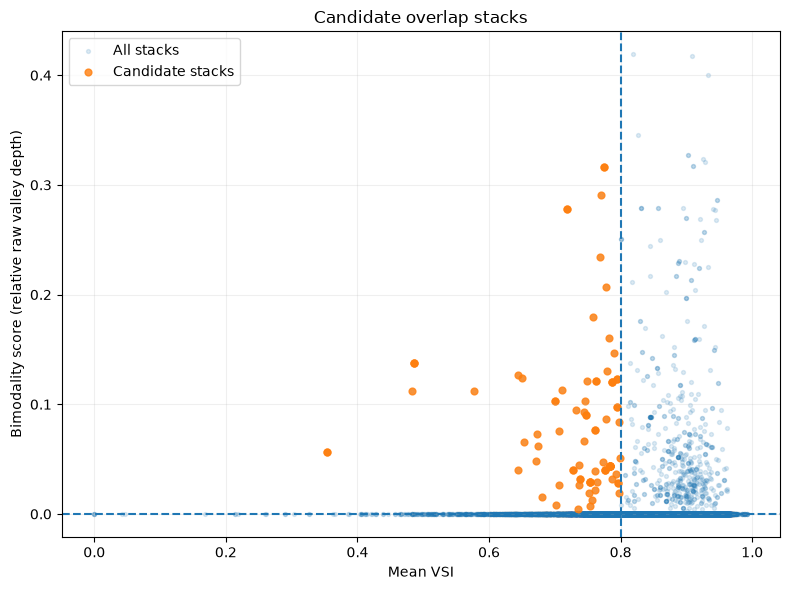

In [26]:
# =============================================================================
# PLOT 10 — HIGHLIGHT CANDIDATES
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


ax.scatter(
    qc_df[
        "mean_vsi"
    ],
    qc_df[
        "ordered_bimodality_score"
    ],
    s=8,
    alpha=0.15,
    label="All stacks",
)


ax.scatter(
    candidate_df[
        "mean_vsi"
    ],
    candidate_df[
        "ordered_bimodality_score"
    ],
    s=24,
    alpha=0.8,
    label="Candidate stacks",
)


ax.axvline(
    VSI_CUTOFF,
    linestyle="--",
)


ax.axhline(
    BIMODALITY_SCORE_CUTOFF,
    linestyle="--",
)


ax.set_xlabel(
    "Mean VSI"
)

ax.set_ylabel(
    "Bimodality score (relative raw valley depth)"
)

ax.set_title(
    "Candidate overlap stacks"
)

ax.legend()

ax.grid(
    alpha=0.2
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "10_candidate_stacks_scatter.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [27]:
# =============================================================================
# EXPLORATORY VS STRICT BIMODALITY
# =============================================================================

qc_df[
    "bimodality_score_gt_zero"
] = (
    qc_df[
        "ordered_bimodality_score"
    ]
    > 0
)


qc_df[
    "bimodality_valley_15pct"
] = (
    qc_df[
        "ordered_bimodality_score"
    ]
    >= 0.15
)


comparison = pd.Series(
    {
        "Score > 0":
            int(
                qc_df[
                    "bimodality_score_gt_zero"
                ].sum()
            ),

        "Valley depth >= 0.15":
            int(
                qc_df[
                    "bimodality_valley_15pct"
                ].sum()
            ),
    }
)


print(
    comparison
)

Score > 0               638
Valley depth >= 0.15     75
dtype: int64


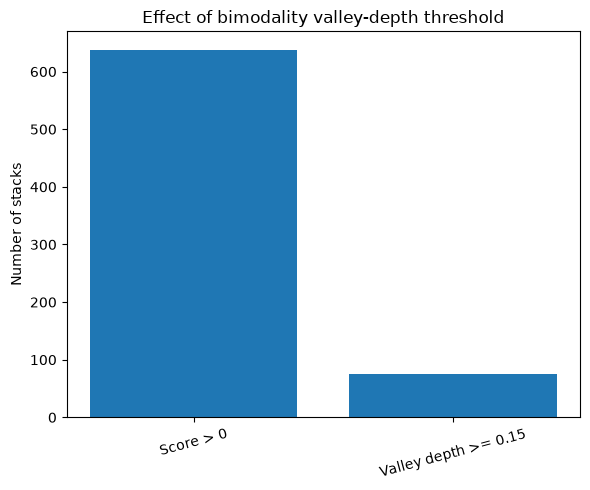

In [28]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)


ax.bar(
    comparison.index,
    comparison.values,
)


ax.set_ylabel(
    "Number of stacks"
)

ax.set_title(
    "Effect of bimodality valley-depth threshold"
)


ax.tick_params(
    axis="x",
    rotation=15,
)


fig.tight_layout()


fig.savefig(
    OUT_DIR
    / "11_bimodality_threshold_comparison.png",
    dpi=200,
    bbox_inches="tight",
)


plt.show()

In [29]:
# =============================================================================
# SAVE RESULTS
# =============================================================================

qc_df.to_csv(
    OUT_DIR
    / "merged_vsi_two_maxima_bimodality_all_qc.csv",
    index=False,
)


candidate_df.to_csv(
    OUT_DIR
    / "candidate_stacks_vsi_le_0.7_bimodality_gt_0.csv",
    index=False,
)


sensitivity_df.to_csv(
    OUT_DIR
    / "vsi_cutoff_sensitivity.csv",
    index=False,
)


association_df.to_csv(
    OUT_DIR
    / "vsi_bimodality_association_across_cutoffs.csv",
    index=False,
)


print(
    "Saved all analysis tables to:"
)

print(
    OUT_DIR
)

Saved all analysis tables to:
/data/gent/vo/000/gvo00070/vsc48277/yujin_project/40k_subset_0_cellpose_fullcell_stitch3d_tiled_filtered/vsi_bimodality_analysis


In [30]:
# =============================================================================
# FINAL SUMMARY
# =============================================================================

n_total = len(
    qc_df
)

n_low = int(
    qc_df[
        "low_vsi"
    ].sum()
)

n_bimodal = int(
    qc_df[
        "bimodality_positive"
    ].sum()
)

n_both = int(
    qc_df[
        "both"
    ].sum()
)

n_strict = int(
    (
        qc_df[
            "ordered_bimodality_score"
        ]
        >= 0.15
    ).sum()
)


print("=" * 70)

print(
    "VSI + TWO-MAXIMA BIMODALITY SUMMARY"
)

print("=" * 70)


print(
    f"QC-passed stacks: "
    f"{n_total:,}"
)


print(
    f"Mean VSI <= {VSI_CUTOFF}: "
    f"{n_low:,} "
    f"({n_low / n_total * 100:.2f}%)"
)


print(
    f"Bimodality score > 0: "
    f"{n_bimodal:,} "
    f"({n_bimodal / n_total * 100:.2f}%)"
)


print(
    f"Bimodality score >= 0.15: "
    f"{n_strict:,} "
    f"({n_strict / n_total * 100:.2f}%)"
)


print(
    f"Low VSI + score > 0: "
    f"{n_both:,} "
    f"({n_both / n_total * 100:.2f}%)"
)


print(
    "\nNew bimodality score definition:"
)

print(
    "(lower peak intensity - valley intensity) "
    "/ lower peak intensity"
)


print(
    "\nValley is evaluated only when the two "
    "highest-intensity z-layers are at least "
    "3 z-indices apart."
)

print("=" * 70)

VSI + TWO-MAXIMA BIMODALITY SUMMARY
QC-passed stacks: 65,317
Mean VSI <= 0.8: 4,637 (7.10%)
Bimodality score > 0: 638 (0.98%)
Bimodality score >= 0.15: 75 (0.11%)
Low VSI + score > 0: 87 (0.13%)

New bimodality score definition:
(lower peak intensity - valley intensity) / lower peak intensity

Valley is evaluated only when the two highest-intensity z-layers are at least 3 z-indices apart.


In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
import zarr

from skimage.segmentation import find_boundaries


# =============================================================================
# 1. SETTINGS
# =============================================================================

ZARR_PATH = (
    PROJECT_DIR
    / "40k_subset_0.zarr"
)

IMAGE_ARRAY_PATH = (
    "images/clahe_DAPI_PolyT/0"
)

MAXPROJ_ARRAY_PATH = (
    "labels/"
    "segmentation_mask_optimized_maxproj_45k/"
    "0"
)

DAPI_INTENSITY_CSV = (
    STITCH_OUTPUT_DIR
    / "dapi_maxproj_mask_z_intensity_profiles"
    / "stack_z_intensity_maxproj_mask_dapi.csv"
)

STITCHED_MASK_DIR = (
    STITCH_OUTPUT_DIR
    / "stitched_masks"
)

MASK_PATTERN = "mask_z{z}.tif"

INTENSITY_COLUMN = (
    "fixed_mask_mean_polyt_intensity"
)


IMAGE_LAYOUT = "czyx"

DAPI_CHANNEL = 0
POLYT_CHANNEL = 1

N_Z = 7

DISPLAY_PADDING = 40

# Change if you want more/fewer candidates
N_CANDIDATES_TO_PLOT = 30


CANDIDATE_GALLERY_DIR = (
    OUT_DIR
    / "candidate_gallery_two_maxima"
)

PROFILE_DIR = (
    CANDIDATE_GALLERY_DIR
    / "profiles"
)


CANDIDATE_GALLERY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PROFILE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Candidate gallery output:"
)

print(
    CANDIDATE_GALLERY_DIR
)

/kyukon/data/gent/vo/000/gvo00070/vsc48277/yujin_project/napari-sparrow/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Candidate gallery output:
/data/gent/vo/000/gvo00070/vsc48277/yujin_project/40k_subset_0_cellpose_fullcell_stitch3d_tiled_filtered/vsi_bimodality_analysis/candidate_gallery_two_maxima


In [32]:
# =============================================================================
# 2. LOAD POLYT INTENSITY PROFILE TABLE
# =============================================================================

if not DAPI_INTENSITY_CSV.exists():

    raise FileNotFoundError(
        f"DAPI intensity CSV not found:\n"
        f"{DAPI_INTENSITY_CSV}"
    )


intensity_df = pd.read_csv(
    DAPI_INTENSITY_CSV
)


required_intensity_columns = {
    "stack_id",
    "z",
    INTENSITY_COLUMN,
    "maxproj_cell_id",
    "roi_y_min",
    "roi_y_max",
    "roi_x_min",
    "roi_x_max",
}


missing = (
    required_intensity_columns
    - set(
        intensity_df.columns
    )
)


if missing:

    raise ValueError(
        f"Missing columns from intensity CSV:\n"
        f"{missing}"
    )


intensity_df["stack_id"] = pd.to_numeric(
    intensity_df["stack_id"],
    errors="raise",
).astype(
    np.int64
)


intensity_df["z"] = pd.to_numeric(
    intensity_df["z"],
    errors="raise",
).astype(
    int
)


intensity_df[
    INTENSITY_COLUMN
] = pd.to_numeric(
    intensity_df[
        INTENSITY_COLUMN
    ],
    errors="coerce",
)


print(
    "Intensity rows:",
    len(
        intensity_df
    )
)


Intensity rows: 476021


In [33]:
# =============================================================================
# 3. HELPERS
# =============================================================================

def read_image_crop(
    array,
    channel,
    z,
    y_start,
    y_stop,
    x_start,
    x_stop,
):

    indexing = []

    for axis_name in IMAGE_LAYOUT:

        if axis_name == "c":

            indexing.append(
                channel
            )

        elif axis_name == "z":

            indexing.append(
                z
            )

        elif axis_name == "y":

            indexing.append(
                slice(
                    y_start,
                    y_stop,
                )
            )

        elif axis_name == "x":

            indexing.append(
                slice(
                    x_start,
                    x_stop,
                )
            )


    crop = np.squeeze(
        np.asarray(
            array[
                tuple(
                    indexing
                )
            ]
        )
    )


    if crop.ndim != 2:

        raise ValueError(
            f"Expected 2D image crop "
            f"at z{z}, got {crop.shape}"
        )


    return crop


def first_unique_value(
    dataframe,
    column,
):

    if column not in dataframe.columns:

        raise ValueError(
            f"Column missing: "
            f"{column}"
        )


    values = (
        dataframe[
            column
        ]
        .dropna()
        .unique()
    )


    if len(values) == 0:

        raise ValueError(
            f"No valid value found "
            f"for {column}"
        )


    if len(values) > 1:

        raise ValueError(
            f"Multiple values for "
            f"{column}: {values}"
        )


    return values[0]

In [34]:
# =============================================================================
# 4. OPEN ZARR SAFELY
#
# IMPORTANT:
# Nothing here loads the full 45k x 45k label into memory.
# =============================================================================

zarr_root = zarr.open(
    str(
        ZARR_PATH
    ),
    mode="r",
)


# -----------------------------------------------------------------------------
# DAPI + PolyT image
# -----------------------------------------------------------------------------

if IMAGE_ARRAY_PATH not in zarr_root:

    raise KeyError(
        f"Image array not found:\n"
        f"{IMAGE_ARRAY_PATH}"
    )


image_array = (
    zarr_root[
        IMAGE_ARRAY_PATH
    ]
)


print(
    "\nImage array:"
)

print(
    "  shape:",
    image_array.shape,
)

print(
    "  chunks:",
    image_array.chunks,
)

print(
    "  dtype:",
    image_array.dtype,
)


# -----------------------------------------------------------------------------
# Maximum-projection segmentation
# -----------------------------------------------------------------------------

if MAXPROJ_ARRAY_PATH not in zarr_root:

    raise KeyError(
        f"Max-projection array not found:\n"
        f"{MAXPROJ_ARRAY_PATH}"
    )


maxproj_array = (
    zarr_root[
        MAXPROJ_ARRAY_PATH
    ]
)


print(
    "\nMax-projection label:"
)

print(
    "  shape:",
    maxproj_array.shape,
)

print(
    "  chunks:",
    maxproj_array.chunks,
)

print(
    "  dtype:",
    maxproj_array.dtype,
)



Image array:
  shape: (2, 7, 45000, 45000)
  chunks: (1, 1, 4096, 4096)
  dtype: uint16

Max-projection label:
  shape: (45000, 45000)
  chunks: (2048, 2048)
  dtype: int32


In [35]:
# =============================================================================
# 5. OPEN STITCHED MASKS AS MEMORY MAPS
# =============================================================================

stitched_masks = []

expected_shape = None


for z in range(
    N_Z
):

    mask_path = (
        STITCHED_MASK_DIR
        / MASK_PATTERN.format(
            z=z
        )
    )


    if not mask_path.exists():

        raise FileNotFoundError(
            f"Missing stitched mask:\n"
            f"{mask_path}"
        )


    mask = tifffile.memmap(
        str(
            mask_path
        )
    )


    mask = np.squeeze(
        mask
    )


    if mask.ndim != 2:

        raise ValueError(
            f"Expected 2D mask at z{z}, "
            f"got {mask.shape}"
        )


    if expected_shape is None:

        expected_shape = (
            mask.shape
        )

    elif mask.shape != expected_shape:

        raise ValueError(
            f"Mask shape mismatch at z{z}: "
            f"{mask.shape}"
        )


    stitched_masks.append(
        mask
    )


    print(
        f"Opened stitched mask z{z}: "
        f"{mask.shape}"
    )


IMAGE_HEIGHT, IMAGE_WIDTH = (
    expected_shape
)

Opened stitched mask z0: (45000, 45000)
Opened stitched mask z1: (45000, 45000)
Opened stitched mask z2: (45000, 45000)
Opened stitched mask z3: (45000, 45000)
Opened stitched mask z4: (45000, 45000)
Opened stitched mask z5: (45000, 45000)
Opened stitched mask z6: (45000, 45000)


In [36]:
# =============================================================================
# 6. SELECT CANDIDATES TO PLOT
# =============================================================================

plot_candidate_df = (
    candidate_df
    .sort_values(
        [
            "ordered_bimodality_score",
            "mean_vsi",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .head(
        N_CANDIDATES_TO_PLOT
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nCandidates to plot:",
    len(
        plot_candidate_df
    )
)


columns_to_show = [
    "stack_id",
    "mean_vsi",
    "n_vsi_pixels",
    "ordered_bimodality_score",
    "raw_valley_depth",
    "peak_1_z",
    "valley_z",
    "peak_2_z",
    "peak_distance",
    "is_ordered_bimodal",
]


columns_to_show = [
    column
    for column in columns_to_show
    if column
    in plot_candidate_df.columns
]


display(
    plot_candidate_df[
        columns_to_show
    ]
)



Candidates to plot: 30


,stack_id,mean_vsi,n_vsi_pixels,ordered_bimodality_score,raw_valley_depth,peak_1_z,valley_z,peak_2_z,peak_distance,is_ordered_bimodal
0,30237,0.774664,145.0,0.316479,0.316479,1,4,6,5,True
1,67047,0.774664,145.0,0.316479,0.316479,1,4,6,5,True
2,12480,0.770624,79.0,0.290404,0.290404,1,4,6,5,True
3,1352,0.719113,166.0,0.278436,0.278436,2,4,6,4,True
4,48362,0.719113,166.0,0.278436,0.278436,2,4,6,4,True
5,53942,0.768001,47.0,0.233925,0.233925,2,4,6,4,True
6,43040,0.777810,145.0,0.206776,0.206776,2,4,6,4,True
7,3563,0.757625,194.0,0.179521,0.179521,1,3,6,5,True
8,67646,0.782835,86.0,0.160743,0.160743,1,5,6,5,True
9,1337,0.789969,15.0,0.146587,0.146587,3,4,6,3,True


In [37]:
# =============================================================================
# 7. CREATE DAPI + POLYT Z-STACK GALLERIES
# =============================================================================

for (
    rank,
    candidate_row,
) in plot_candidate_df.iterrows():

    stack_id = int(
        candidate_row[
            "stack_id"
        ]
    )


    mean_vsi = float(
        candidate_row[
            "mean_vsi"
        ]
    )


    ordered_score = float(
        candidate_row[
            "ordered_bimodality_score"
        ]
    )


    peak_1_z = int(
        candidate_row[
            "peak_1_z"
        ]
    )


    peak_2_z = int(
        candidate_row[
            "peak_2_z"
        ]
    )


    valley_z = int(
        candidate_row[
            "valley_z"
        ]
    )


    peak_distance = int(
        candidate_row[
            "peak_distance"
        ]
    )


    if (
        "raw_valley_depth"
        in candidate_row.index
    ):

        raw_valley_depth = float(
            candidate_row[
                "raw_valley_depth"
            ]
        )

    else:

        raw_valley_depth = (
            ordered_score
        )


    # =========================================================================
    # 7A. GET RAW POLYT PROFILE
    # =========================================================================

    stack_profile = (
        intensity_df.loc[
            intensity_df[
                "stack_id"
            ]
            == stack_id
        ]
        .sort_values(
            "z"
        )
        .reset_index(
            drop=True
        )
    )


    if len(
        stack_profile
    ) != N_Z:

        print(
            f"Skipping stack {stack_id}: "
            f"found {len(stack_profile)} "
            f"z rows."
        )

        continue


    z_values = (
        stack_profile[
            "z"
        ]
        .to_numpy(
            dtype=int
        )
    )


    if not np.array_equal(
        z_values,
        np.arange(
            N_Z
        ),
    ):

        print(
            f"Skipping stack {stack_id}: "
            f"incomplete z profile."
        )

        continue


    polyt_intensities = (
        stack_profile[
            INTENSITY_COLUMN
        ]
        .to_numpy(
            dtype=float
        )
    )


    # =========================================================================
    # 7B. MAXPROJ CELL + BOUNDING BOX
    # =========================================================================

    maxproj_cell_id = int(
        first_unique_value(
            stack_profile,
            "maxproj_cell_id",
        )
    )


    mask_y_min = int(
        first_unique_value(
            stack_profile,
            "roi_y_min",
        )
    )


    mask_y_max = int(
        first_unique_value(
            stack_profile,
            "roi_y_max",
        )
    )


    mask_x_min = int(
        first_unique_value(
            stack_profile,
            "roi_x_min",
        )
    )


    mask_x_max = int(
        first_unique_value(
            stack_profile,
            "roi_x_max",
        )
    )


    # =========================================================================
    # 7C. DISPLAY CROP
    # =========================================================================

    crop_y_min = max(
        0,
        mask_y_min
        - DISPLAY_PADDING,
    )


    crop_y_max = min(
        IMAGE_HEIGHT,
        mask_y_max
        + DISPLAY_PADDING,
    )


    crop_x_min = max(
        0,
        mask_x_min
        - DISPLAY_PADDING,
    )


    crop_x_max = min(
        IMAGE_WIDTH,
        mask_x_max
        + DISPLAY_PADDING,
    )


    # =========================================================================
    # 7D. READ ONLY SMALL MAXPROJ CROP
    #
    # NO full 45k label is loaded into RAM.
    # =========================================================================

    maxproj_crop = np.asarray(
        maxproj_array[
            crop_y_min:
            crop_y_max,

            crop_x_min:
            crop_x_max,
        ]
    )


    maxproj_crop = np.squeeze(
        maxproj_crop
    )


    if maxproj_crop.ndim != 2:

        raise ValueError(
            f"Expected 2D maxproj crop, "
            f"got {maxproj_crop.shape}"
        )


    fixed_roi_mask = (
        maxproj_crop
        == maxproj_cell_id
    )


    if not fixed_roi_mask.any():

        print(
            f"Skipping stack {stack_id}: "
            f"maxproj cell "
            f"{maxproj_cell_id} "
            f"not found in local crop."
        )

        continue


    fixed_boundary = find_boundaries(
        fixed_roi_mask,
        connectivity=1,
        mode="inner",
    )


    # =========================================================================
    # 7E. CREATE Z-STACK FIGURE
    # =========================================================================

    figure, axes = plt.subplots(
        N_Z,
        2,
        figsize=(
            10,
            N_Z * 4,
        ),
        facecolor="white",
    )


    for z in range(
        N_Z
    ):

        # ---------------------------------------------------------------------
        # Read ONLY this local image crop
        # ---------------------------------------------------------------------

        dapi_crop = read_image_crop(
            array=image_array,
            channel=DAPI_CHANNEL,
            z=z,
            y_start=crop_y_min,
            y_stop=crop_y_max,
            x_start=crop_x_min,
            x_stop=crop_x_max,
        )


        polyt_crop = read_image_crop(
            array=image_array,
            channel=POLYT_CHANNEL,
            z=z,
            y_start=crop_y_min,
            y_stop=crop_y_max,
            x_start=crop_x_min,
            x_stop=crop_x_max,
        )


        # ---------------------------------------------------------------------
        # Current stitched segmentation
        # ---------------------------------------------------------------------

        label_crop = np.asarray(
            stitched_masks[
                z
            ][
                crop_y_min:
                crop_y_max,

                crop_x_min:
                crop_x_max,
            ]
        )


        current_mask = (
            label_crop
            == stack_id
        )


        current_boundary = (
            find_boundaries(
                current_mask,
                connectivity=1,
                mode="inner",
            )
        )


        current_area = int(
            current_mask.sum()
        )


        overlap_pixels = int(
            np.count_nonzero(
                current_mask
                &
                fixed_roi_mask
            )
        )


        # ---------------------------------------------------------------------
        # Mark peak / valley z
        # ---------------------------------------------------------------------

        if z == peak_1_z:

            role_text = (
                "PEAK 1"
            )

        elif z == peak_2_z:

            role_text = (
                "PEAK 2"
            )

        elif z == valley_z:

            role_text = (
                "VALLEY"
            )

        else:

            role_text = "-"


        # ---------------------------------------------------------------------
        # Draw DAPI + PolyT
        # ---------------------------------------------------------------------

        panels = [
            (
                dapi_crop,
                "DAPI",
            ),
            (
                polyt_crop,
                "PolyT",
            ),
        ]


        for (
            column,
            (
                image_crop,
                channel_name,
            ),
        ) in enumerate(
            panels
        ):

            axis = axes[
                z,
                column
            ]


            # No percentile preprocessing or manual intensity manipulation.
            axis.imshow(
                image_crop,
                cmap="gray",
                interpolation="nearest",
            )


            # -------------------------------------------------------------
            # RED = fixed max-projection segmentation
            # -------------------------------------------------------------

            red_overlay = np.zeros(
                (
                    fixed_boundary.shape[0],
                    fixed_boundary.shape[1],
                    4,
                ),
                dtype=np.float32,
            )


            red_overlay[
                fixed_boundary
            ] = [
                1.0,
                0.0,
                0.0,
                1.0,
            ]


            axis.imshow(
                red_overlay,
                interpolation="nearest",
            )


            # -------------------------------------------------------------
            # CYAN = stitched segmentation at this z
            # -------------------------------------------------------------

            if current_boundary.any():

                cyan_overlay = np.zeros(
                    (
                        current_boundary.shape[0],
                        current_boundary.shape[1],
                        4,
                    ),
                    dtype=np.float32,
                )


                cyan_overlay[
                    current_boundary
                ] = [
                    0.0,
                    1.0,
                    1.0,
                    1.0,
                ]


                axis.imshow(
                    cyan_overlay,
                    interpolation="nearest",
                )


            axis.set_title(
                f"z{z} | "
                f"{channel_name} | "
                f"{role_text}\n"
                f"DAPI mean="
                f"{polyt_intensities[z]:.2f} | "
                f"stitched area="
                f"{current_area} | "
                f"overlap="
                f"{overlap_pixels}",
                fontsize=9,
            )


            axis.axis(
                "off"
            )


    figure.suptitle(
        f"Rank {rank + 1} | "
        f"stack_id={stack_id}\n"
        f"mean VSI="
        f"{mean_vsi:.4f} | "
        f"bimodality score="
        f"{ordered_score:.4f} | "
        f"raw valley depth="
        f"{raw_valley_depth:.4f}\n"
        f"peak1=z{peak_1_z} | "
        f"valley=z{valley_z} | "
        f"peak2=z{peak_2_z} | "
        f"distance={peak_distance}\n"
        f"Red = fixed max-projection mask | "
        f"Cyan = stitched segmentation",
        fontsize=13,
    )


    figure.tight_layout(
        rect=[
            0,
            0,
            1,
            0.91,
        ]
    )


    image_output_path = (
        CANDIDATE_GALLERY_DIR
        / (
            f"rank_"
            f"{rank + 1:03d}_"
            f"stack_"
            f"{stack_id}_"
            f"dapi_polyt_zstack.png"
        )
    )


    figure.savefig(
        image_output_path,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )


    plt.close(
        figure
    )


    # =========================================================================
    # 7F. RAW POLYT INTENSITY PROFILE
    # =========================================================================

    figure, axis = plt.subplots(
        figsize=(
            8,
            5.5,
        ),
        facecolor="white",
    )


    axis.plot(
        z_values,
        polyt_intensities,
        marker="o",
        linewidth=2,
        label=(
            "Fixed-mask mean DAPI"
        ),
    )


    # -------------------------------------------------------------------------
    # Selected two maxima
    # -------------------------------------------------------------------------

    axis.scatter(
        [
            peak_1_z,
            peak_2_z,
        ],
        [
            polyt_intensities[
                peak_1_z
            ],
            polyt_intensities[
                peak_2_z
            ],
        ],
        marker="^",
        s=150,
        zorder=5,
        label=(
            "Two highest intensities"
        ),
    )


    # -------------------------------------------------------------------------
    # Selected valley
    # -------------------------------------------------------------------------

    axis.scatter(
        [
            valley_z
        ],
        [
            polyt_intensities[
                valley_z
            ]
        ],
        marker="v",
        s=150,
        zorder=5,
        label="Valley",
    )


    # -------------------------------------------------------------------------
    # Annotate every z
    # -------------------------------------------------------------------------

    for (
        z,
        intensity,
    ) in zip(
        z_values,
        polyt_intensities,
    ):

        if z == peak_1_z:

            label = (
                f"Peak 1\n"
                f"z{z}\n"
                f"{intensity:.1f}"
            )

        elif z == peak_2_z:

            label = (
                f"Peak 2\n"
                f"z{z}\n"
                f"{intensity:.1f}"
            )

        elif z == valley_z:

            label = (
                f"Valley\n"
                f"z{z}\n"
                f"{intensity:.1f}"
            )

        else:

            label = (
                f"z{z}\n"
                f"{intensity:.1f}"
            )


        axis.annotate(
            label,
            xy=(
                z,
                intensity,
            ),
            xytext=(
                0,
                10,
            ),
            textcoords=(
                "offset points"
            ),
            ha="center",
            fontsize=8,
        )


    axis.set_xticks(
        range(
            N_Z
        )
    )


    axis.set_xlabel(
        "z-layer"
    )


    axis.set_ylabel(
        "Mean DAPI intensity "
        "inside fixed max-projection mask"
    )


    axis.set_title(
        f"stack_id={stack_id}\n"
        f"mean VSI="
        f"{mean_vsi:.4f} | "
        f"bimodality score="
        f"{ordered_score:.4f}\n"
        f"peak distance="
        f"{peak_distance} | "
        f"relative valley depth="
        f"{raw_valley_depth:.3f}"
    )


    axis.grid(
        alpha=0.25
    )


    axis.legend(
        fontsize=8
    )


    figure.tight_layout()


    profile_output_path = (
        PROFILE_DIR
        / (
            f"rank_"
            f"{rank + 1:03d}_"
            f"stack_"
            f"{stack_id}_"
            f"dapi_profile.png"
        )
    )


    figure.savefig(
        profile_output_path,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )


    plt.close(
        figure
    )


    print(
        f"Saved "
        f"{rank + 1}/"
        f"{len(plot_candidate_df)} | "
        f"stack_id={stack_id} | "
        f"score={ordered_score:.4f}"
    )

Saved 1/30 | stack_id=30237 | score=0.3165
Saved 2/30 | stack_id=67047 | score=0.3165
Saved 3/30 | stack_id=12480 | score=0.2904
Saved 4/30 | stack_id=1352 | score=0.2784
Saved 5/30 | stack_id=48362 | score=0.2784
Saved 6/30 | stack_id=53942 | score=0.2339
Saved 7/30 | stack_id=43040 | score=0.2068
Saved 8/30 | stack_id=3563 | score=0.1795
Saved 9/30 | stack_id=67646 | score=0.1607
Saved 10/30 | stack_id=1337 | score=0.1466
Saved 11/30 | stack_id=480 | score=0.1377
Saved 12/30 | stack_id=639 | score=0.1377
Saved 13/30 | stack_id=48091 | score=0.1377
Saved 14/30 | stack_id=55516 | score=0.1307
Saved 15/30 | stack_id=48203 | score=0.1265
Saved 16/30 | stack_id=50606 | score=0.1241
Saved 17/30 | stack_id=45820 | score=0.1227
Saved 18/30 | stack_id=62431 | score=0.1227
Saved 19/30 | stack_id=53805 | score=0.1210
Saved 20/30 | stack_id=30494 | score=0.1210
Saved 21/30 | stack_id=61530 | score=0.1210
Saved 22/30 | stack_id=25017 | score=0.1205
Saved 23/30 | stack_id=27299 | score=0.1205
Save

In [38]:
# =============================================================================
# 8. SAVE TABLE OF PLOTTED CANDIDATES
# =============================================================================

plot_candidate_df.to_csv(
    CANDIDATE_GALLERY_DIR
    / "plotted_candidates.csv",
    index=False,
)


print(
    "\nDone!"
)

print(
    "Z-stack plots:"
)

print(
    CANDIDATE_GALLERY_DIR
)

print(
    "\nProfile plots:"
)

print(
    PROFILE_DIR
)


Done!
Z-stack plots:
/data/gent/vo/000/gvo00070/vsc48277/yujin_project/40k_subset_0_cellpose_fullcell_stitch3d_tiled_filtered/vsi_bimodality_analysis/candidate_gallery_two_maxima

Profile plots:
/data/gent/vo/000/gvo00070/vsc48277/yujin_project/40k_subset_0_cellpose_fullcell_stitch3d_tiled_filtered/vsi_bimodality_analysis/candidate_gallery_two_maxima/profiles
